In [31]:
import pandas as pd
import re
from datetime import datetime
import numpy as np
from plotnine import ggplot, geom_bar, aes, geom_col, labs, theme, element_blank, element_text, scale_x_datetime
import os

In [4]:
# Filters applied to BVBRC when downloading the metadata
# Influenza A Virus
# H_Type: 5
# Collection Year: 2022, 2023, 2024
# Geographic Group: North America
# Host Group: Avian

In [5]:
#LATESTBVBRC = "./metadata/sequence_metadata/bvbrc_metadata_2022-2024.csv"
LATESTBVBRC = "./metadata/sequence_metadata/bvbrc_metadata_2021-2024.csv"

In [6]:
data_bvbrc = pd.read_csv(LATESTBVBRC, sep = ",")

/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_8314/3111213428.py:1: DtypeWarning: Columns (30,40,42,44,83) have mixed types. Specify dtype option on import or set low_memory=False.


In [7]:
# Function 1: making Collection Date a datetime object
def format_date(datestr):
    i = str(datestr)
    date_object = datetime.strptime(i, '%Y-%m-%d')
    return (date_object)

In [8]:
# Function 3: Detemining duplicate strains
def to_dedupe(df):
    strain_count = df["strain_segment"].value_counts()
    strain_count = strain_count.rename_axis("strain_segment").reset_index()
    duplicate_strains = []
    for strain, count in strain_count.iterrows():
        if count['count'] > 1:
            duplicate_strains.append(count['strain_segment'])
    duplicates = pd.DataFrame(duplicate_strains)
    return(duplicates)

In [9]:
# Step 1: Clean and organize the metadata

In [12]:
print(len(data_bvbrc))

# August 13, 2024 pull - 15,865 seq

# January 21, 2025 pull - 17,233 seq

# May 28, 2025 pull - 47,110 seq

47110


In [34]:
# This code (courtesy of Chat GPT; thank you, Chat) creates a new dataframe with a "Collection_datetime" object that has reformatted dates

bvbrc_filtered = data_bvbrc.copy()

bvbrc_filtered['Collection_datetime'] = None

for idx, i in enumerate(bvbrc_filtered["Collection Date"]):
    # Check if the date format is '%b-%Y' (e.g., 'Jan-2023')
    try:
        if datetime.strptime(i, '%b-%Y'):
            # Convert the date to the format '%Y-%m-15' (e.g., '2023-01-15')
            formatted_date = datetime.strptime(i, '%b-%Y').strftime('%Y-%m-15')
            # Update the DataFrame with the formatted date
            bvbrc_filtered.at[idx, 'Collection_datetime'] = formatted_date
    except ValueError:
        pass

    # Check if the date format is '%d-%b-%Y' (e.g., '25-Jan-2023')
    try:
        if datetime.strptime(i, '%d-%b-%Y'):
            # Convert the date to the format '%Y-%m-%d' (e.g., '2023-01-25')
            formatted_date = datetime.strptime(i, '%d-%b-%Y').strftime('%Y-%m-%d')
            # Update the DataFrame with the formatted date
            bvbrc_filtered.at[idx, 'Collection_datetime'] = formatted_date
    except ValueError:
        pass

    # Check if the date format is '%m/%d/%y' (e.g. 3/4/23)
    try:
        if datetime.strptime(i, '%m/%d/%y'):
            formatted_date = datetime.strptime(i, '%m/%d/%y').strftime('%Y-%m-%d')
            bvbrc_filtered.at[idx, 'Collection_datetime'] = formatted_date
    except ValueError:
        pass

    # Check if the date format is ''%Y-%m-%d'
    try:
        if datetime.strptime(i, '%Y-%m-%d'):
            formatted_date = datetime.strptime(i, '%Y-%m-%d').strftime('%Y-%m-%d')
            bvbrc_filtered.at[idx, 'Collection_datetime'] = formatted_date
    except ValueError:
        pass

print(len(bvbrc_filtered)) # 17233 length

47110


In [35]:
# Need a column with ambiguous dates for BEAST, so adding that 

bvbrc_filtered['beast_collectdate'] = None

for idx, i in enumerate(bvbrc_filtered["Collection Date"]):
    # Check if the date format is '%b-%Y' (e.g., 'Jan-2023')
    try:
        if datetime.strptime(i, '%b-%Y'):
            # Convert the date to the format '%Y-%m-XX'
            formatted_date = datetime.strptime(i, '%b-%Y').strftime('%Y-%m-XX')
            # Update the DataFrame with the formatted date
            bvbrc_filtered.at[idx, 'beast_collectdate'] = formatted_date
    except ValueError:
        pass

    # Check if the date format is '%d-%b-%Y' (e.g., '25-Jan-2023')
    try:
        if datetime.strptime(i, '%d-%b-%Y'):
            # Convert the date to the format '%Y-%m-%d' (e.g., '2023-01-25')
            formatted_date = datetime.strptime(i, '%d-%b-%Y').strftime('%Y-%m-%d')
            # Update the DataFrame with the formatted date
            bvbrc_filtered.at[idx, 'beast_collectdate'] = formatted_date
    except ValueError:
        pass

    # Check if the date format is '%m/%d/%y' (e.g. 3/4/23)
    try:
        if datetime.strptime(i, '%m/%d/%y'):
            formatted_date = datetime.strptime(i, '%m/%d/%y').strftime('%Y-%m-%d')
            bvbrc_filtered.at[idx, 'beast_collectdate'] = formatted_date
    except ValueError:
        pass

    # Check if the date format is ''%Y-%m-%d'
    try:
        if datetime.strptime(i, '%Y-%m-%d'):
            formatted_date = datetime.strptime(i, '%Y-%m-%d').strftime('%Y-%m-%d')
            bvbrc_filtered.at[idx, 'beast_collectdate'] = formatted_date
    except ValueError:
        pass

In [39]:
# Remove dates that only have the year

bvbrc_filtered_1 = bvbrc_filtered[~bvbrc_filtered["Collection Date"].str.match(r"^\d{4}$")]
print(len(bvbrc_filtered_1)) 

# August 2024 pull - 14505 seqs
# January 2025 pull - 15065 seqs
# May 2025 pull - 41250 seqs

41250


In [63]:
# Remove dates before November 1, 2021

bvbrc_filtered_1 = bvbrc_filtered_1[(bvbrc_filtered_1["Collection_datetime"] >= '2021-11-01')]
print(len(bvbrc_filtered_1))

# May 2025 pull - 40651 seqs

40651


In [64]:
# Fix strain name

bvbrc_filtered_2 = bvbrc_filtered_1.copy()

bvbrc_filtered_2["Strain"] = bvbrc_filtered_2["Strain"].str.lower()
bvbrc_filtered_2["Strain"] = bvbrc_filtered_2["Strain"].str.replace("-","")
bvbrc_filtered_2["Strain"] = bvbrc_filtered_2["Strain"].str.replace(" ","")
bvbrc_filtered_2["Strain"] = bvbrc_filtered_2["Strain"].str.replace("_","")
bvbrc_filtered_2["Strain"] = bvbrc_filtered_2["Strain"].str.replace("'", "") # This, specifically, should take care of "ross'sgoose" and "cooper'shawk"

bvbrc_strain = bvbrc_filtered_2.rename({"Strain":"strain"}, axis = 1)

In [65]:
# Make a column that combines strain_segment

# Have to make all float values in Segment into integers while maintaining NaN values
bvbrc_strain["Segment"] = bvbrc_strain["Segment"].replace([np.inf, -np.inf], np.nan)

bvbrc_strain["Segment"] = pd.to_numeric(bvbrc_strain["Segment"], errors='coerce').astype('Int64')
#print(type(bvbrc_strain["Segment"].dtype))

bvbrc_strain["Segment"] = bvbrc_strain["Segment"].astype(str)
bvbrc_strain["Segment"].apply(type)

bvbrc_strain["strain"] = bvbrc_strain["strain"].astype(str)
bvbrc_strain["strain"].apply(type)

bvbrc_strain["strain_segment"] = bvbrc_strain[["strain", "Segment"]].apply(lambda x: '_'.join(x), axis=1)

In [66]:
# Get state from strain name

# Extract state from strain name
strain_split = bvbrc_strain["strain"].str.split(pat = "/", expand = True)
#print(strain_split)

# Add State to ncbi_filtered_1
bvbrc_strain["State"] = strain_split[2]
#bvbrc_strain.head()

In [67]:
state_corrections_dict = {"al":"alabama",
                          "ak":"alaska",
                          "ab":"alberta",
                          "az":"arizona",
                          "ar":"arkansas",
                          "bc":"britishcolumbia",
                          "ca":"california",
                          "co":"colorado",
                          "ct":"connecticut",
                          "districtofcolumbia":"dc",
                          "de":"delaware",
                          "fl":"florida",
                          "ga":"georgia",
                          "hi":"hawaii",
                          "id":"idaho",
                          "il":"illinois",
                          "in":"indiana",
                          "ia":"iowa",
                          "ks":"kansas",
                          "ky":"kentucky",
                          "la":"louisiana",
                          "me":"maine",
                          "mb":"manitoba",
                          "md":"maryland",
                          "ma":"massachusetts",
                          "mi":"michigan",
                          "mn":"minnesota",
                          "ms":"mississippi",
                          "mo":"missouri",
                          "mt":"montana",
                          "ne":"nebraska",
                          "nv":"nevada",
                          "nb":"newbrunswick",
                          "nl":"newfoundland",
                          "nh":"newhampshire",
                          "nj":"newjersey",
                          "nm":"newmexico",
                          "ny":"newyork",
                          "nc":"northcarolina",
                          "nd":"northdakota",
                          "nt":"northwestterritories",
                          "ns":"novascotia",
                          "nu":"nunavut",
                          "oh":"ohio",
                          "ok":"oklahoma",
                          "on":"ontario",
                          "or":"oregon",
                          "pa":"pennsylvania",
                          "pe":"princeedwardisland",
                          "pei":"princeedwardisland",
                          "pr":"puertorico",
                          "qc":"quebec",
                          "ri":"rhodeisland",
                          "sk":"saskatchewan",
                          "sc":"southcarolina",
                          "sd":"southdakota",
                          "tn":"tennessee",
                          "tx":"texas",
                          "ut":"utah",
                          "vt":"vermont",
                          "va":"virginia",
                          "wa":"washington",
                          "wv":"westvirginia",
                          "wi":"wisconsin",
                          "wy":"wyoming",
                          "yt":"yukon",
                          "louisana":"louisiana",
                          "flordia":"florida",
                          "edomex":"mexicostate"
                         }

In [68]:
# Fix the State column

print(set(bvbrc_strain["State"]))

bvbrc_stateadded = bvbrc_strain.copy()

bvbrc_stateadded["State"] = bvbrc_strain["State"].map(state_corrections_dict).fillna(bvbrc_stateadded["State"])

print(set(bvbrc_stateadded["State"]))

{'wi', 'usa', 'oh', 'illinois', 'ca', 'la', 'georgia', 'vermont', 'mo', 'pr', 'hi', 'kansas', 'ms', 'newjersey', 'in', 'az', 'ri', 'nh', 'guanajuato', 'wa', 'newyork', 'mi', 'co', 'me', 'or', 'alaska', 'northdakota', 'al', 'maryland', 'fl', 'ar', 'nc', 'nj', 'ne', 'wisconsin', 'louisana', 'rhodeisland', 'iowa', 'arkansas', 'mt', 'ma', 'ny', 'sd', 'pa', 'va', 'mn', 'california', 'delaware', 'wy', 'nd', 'newhampshire', 'il', 'newmexico', 'ut', 'washington', 'nm', 'tennessee', 'nv', 'indiana', 'alabama', 'virginia', 'vt', 'wyoming', 'michigan', 'oklahoma', 'sc', 'ak', 'connecticut', 'maine', 'montana', 'id', 'florida', 'southdakota', 'louisiana', 'veracruz', 'md', 'kentucky', 'missouri', 'northcarolina', 'southcarolina', 'de', 'ga', 'ia', 'utah', 'minnesota', 'ct', 'wv', 'ky', 'oregon', 'ohio', 'ok', 'texas', 'nan', 'colorado', 'pennsylvania', 'sonora', 'tx', 'tn', 'ks', 'nebraska', 'massachusetts', 'idaho'}
{'kentucky', 'maryland', 'usa', 'westvirginia', 'missouri', 'northcarolina', 'ill

In [69]:
# Just to check in at this point:
# I have added a Collection_datetime column that standardizes the dates in the Collection Date column: bvbrc_filtered
# I have filtered out the sequences that have just year: bvbrc_filtered_1
# I have standarized the Strain column: bvbrc_strain
# I have added a column with strain_segment: bvbrc_strain
# I have added a column with corrected state data: bvbrc_stateadded

In [70]:
# How many samples have fine-scale data in Geographic Location

# location_split = bvbrc_stateadded["Geographic Location"].str.split(pat = ": ", expand = True)
# location_info = location_split.value_counts()

# location_info_axis = ("Country", "Finer Scale")
# location_info = location_info.rename_axis(location_info_axis).reset_index()
# location_info.head()

In [71]:
# Optional: plot the fine scale location data (out of curiousity)
# (
#     ggplot(location_info, aes(x = "Finer Scale", y = "count"))
#     + geom_col()
#     + labs(x = "Location Information", y = "Number of Sequences")
#     + theme(axis_text_x = element_text(rotation = 90))
#     + theme(figure_size=(15,5))
# )
# We have a lot of county or city data for samples from New England (thank you, Wendy Puryear)

In [72]:
# To make a list of bird orders included in the metadata, first determine which bird species are in the metadata
# For the most consistency, use the species defined in the strain name

bvbrc_stateadded["strain_host"] = strain_split[1]

bvbrc_unique_avian_hosts = pd.DataFrame(set(bvbrc_stateadded["strain_host"]))

print(len(bvbrc_unique_avian_hosts)) 

#DATE_UPDATED = "2025-01-27" # 91 unique species names
DATE_UPDATED = "2025-05-28" # 119 unique species names

bvbrc_unique_avian_hosts.to_csv("./metadata/helpful_lists/bvbrc_avian_hosts_updated_" + DATE_UPDATED + ".csv", sep = ',')

119


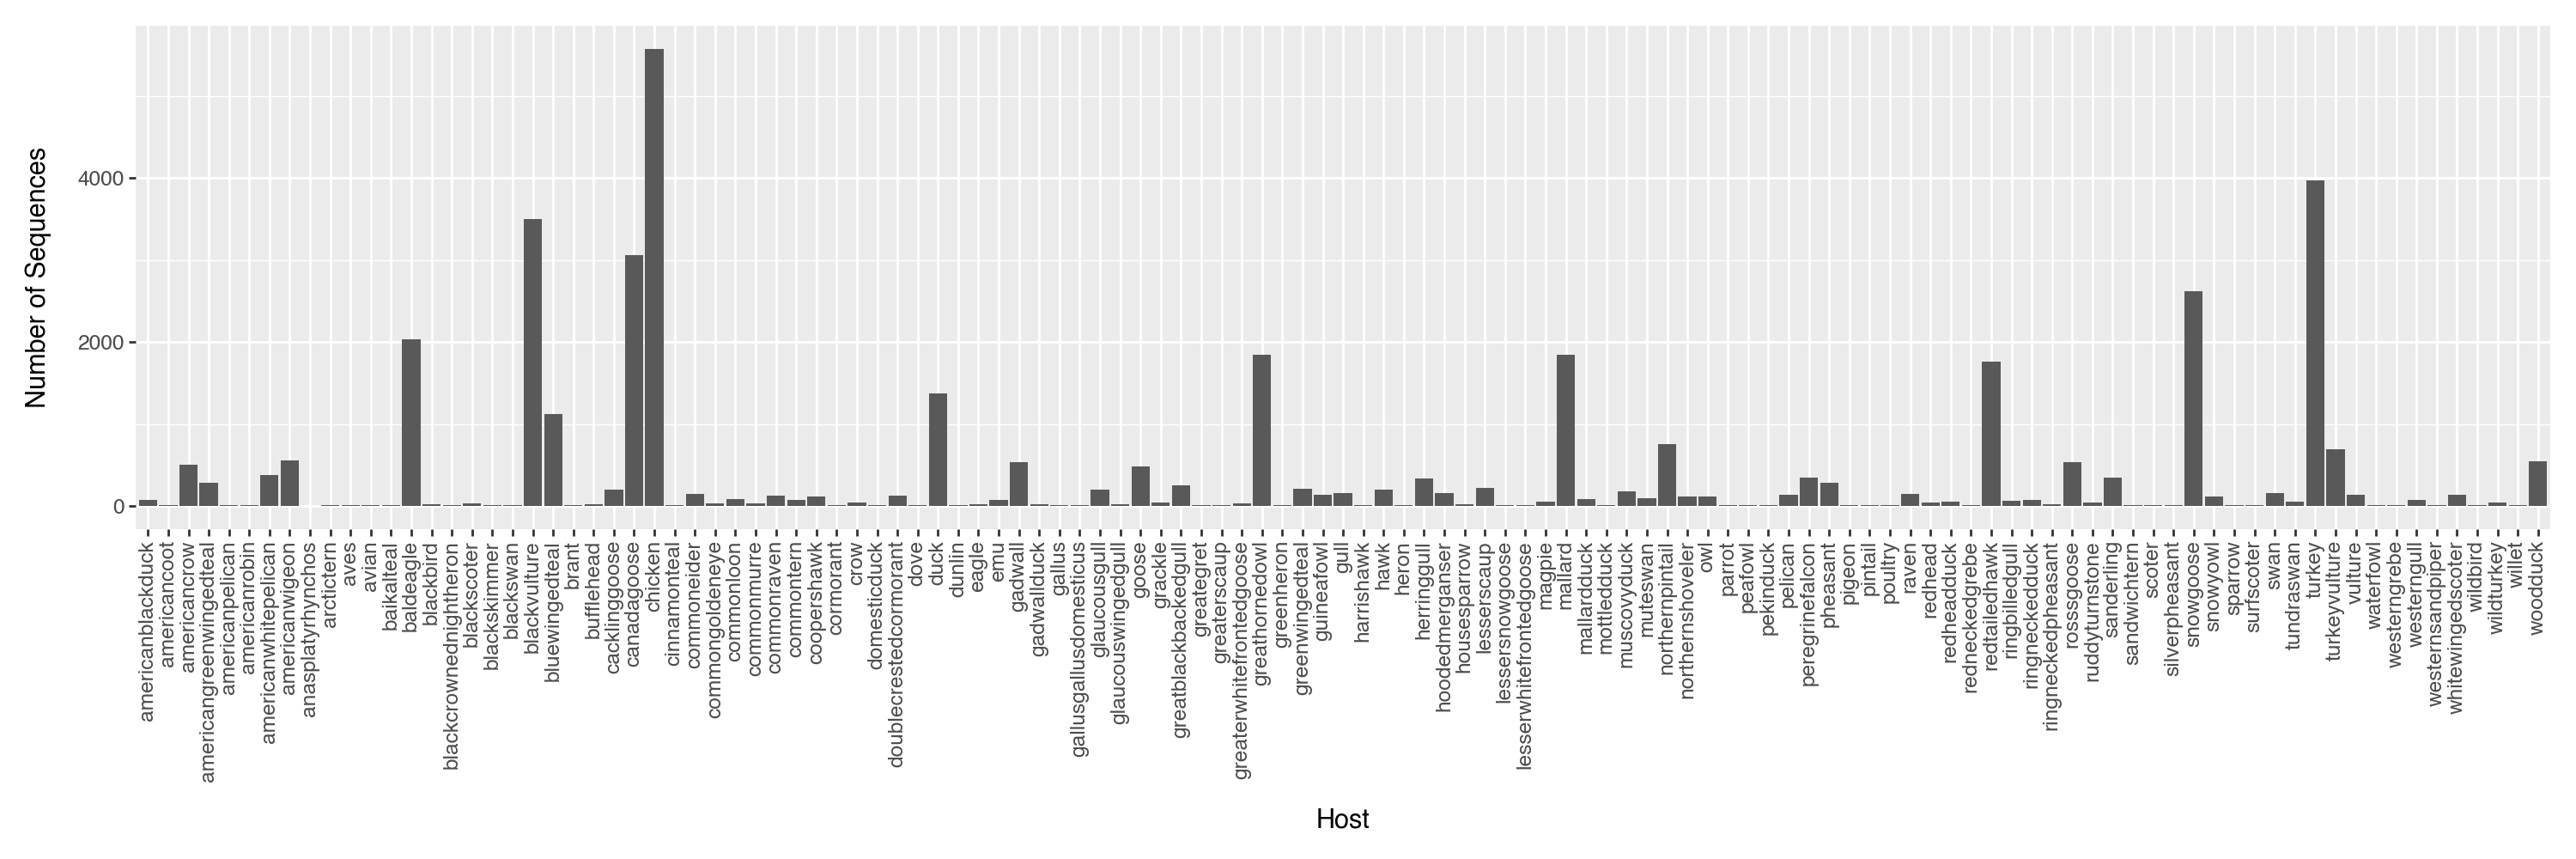

In [73]:
# Optional: Plot the host data

bvbrc_avian_hosts = pd.DataFrame(bvbrc_stateadded["strain_host"])

(
    ggplot(bvbrc_avian_hosts, aes(x = "strain_host"))
    + geom_bar(stat = "count")
    + labs(x = "Host", y = "Number of Sequences")
    + theme(axis_text_x = element_text(rotation = 90))
    + theme(figure_size=(15,5))
)

In [75]:
# Add a column for host bird order and domestic status

birdies = pd.read_csv("./metadata/helpful_lists/NAm_host_list_order-domesticstat.csv", sep = ",", encoding='latin-1')

birdies_dict = birdies.set_index("strain_host").to_dict(orient="index")

bvbrc_state_birdorder = bvbrc_stateadded.copy()

for idx, row in bvbrc_state_birdorder.iterrows():
    # Check if strain_host exists in the dictionary
    strain_host = row["strain_host"]
    if strain_host in birdies_dict:
        bvbrc_state_birdorder.loc[idx, "order"] = birdies_dict[strain_host]["order"]
        bvbrc_state_birdorder.loc[idx, "domesticstatus"] = birdies_dict[strain_host]["domesticstatus"]
        bvbrc_state_birdorder.loc[idx, "corrected_host"] = birdies_dict[strain_host]["corrected_host"]

print(len(bvbrc_state_birdorder)) 

# August 13, 2024 pull - 14505 seq left
# January 21, 2025 pull - 15065 seq left
# May 25, 2025 pull = 40651 seq 

40651


In [76]:
# Check that all rows have a corresponding bird order and corrected host

empty_order = bvbrc_state_birdorder[bvbrc_state_birdorder["order"].isna()]
print(len(empty_order))

empty_corrected_host = bvbrc_state_birdorder[bvbrc_state_birdorder["corrected_host"].isna()]
print(len(empty_corrected_host))

0
0


In [77]:
# Upload a CSV with latitude, longitude, and flyway data for each location

locations_csv = "./metadata/helpful_lists/flywayregions_biggerlist.csv"

lat_long_flyways = pd.read_csv(locations_csv, sep = ',') 

# Turn this CSV into a dictionary

lat_long_flyways_dict = lat_long_flyways.set_index("location").to_dict(orient="index")

In [79]:
# Add a column for flyways

bvbrc_state_birdorder_flyways = bvbrc_state_birdorder.copy()

bvbrc_state_birdorder_flyways["flyway"] = bvbrc_state_birdorder_flyways["State"].map(lambda state: lat_long_flyways_dict.get(state, {}).get("flyway"))

print(len(bvbrc_state_birdorder_flyways)) 

# August 13, 2024 pull - 14505 seq
# January 21, 2025 pull - 15065 seq
# May 25, 2025 pull - 40651 seq

40651


In [80]:
# This is an old, defunct method (because I like dictionaries more than merged CSVs)
# # Add a column for flyways

# # Upload flyways dataframe
# flyways = pd.read_csv("./metadata/helpful_lists/flywayregions.csv", sep = ",", dtype={'location':str})
# column_mapper = {"location":"State"}
# flyways = flyways.rename(mapper = column_mapper, axis = 1)
# flyways["State"] = flyways["State"].str.lower()
# #flyways["State"] = flyways["State"].str.replace(pat = " ", repl = "", regex = False)

# # Add flyways to metadata
# bvbrc_state_birdorder_flyways = pd.merge(bvbrc_state_birdorder, flyways, on = "State", how = "outer") 
# print(len(bvbrc_state_birdorder_flyways)) #Length of this is 14514 (due to 9 states without any sequence data)

In [81]:
# Add columns for latitide and longitude

bvbrc_state_birdorder_flyways["latitude"] = bvbrc_state_birdorder_flyways["State"].map(lambda state: lat_long_flyways_dict.get(state, {}).get("latitude"))
bvbrc_state_birdorder_flyways["longitude"] = bvbrc_state_birdorder_flyways["State"].map(lambda state: lat_long_flyways_dict.get(state, {}).get("longitude"))
bvbrc_state_birdorder_flyways["state_coord"] = bvbrc_state_birdorder_flyways["latitude"].astype(str) + ',' + bvbrc_state_birdorder_flyways["longitude"].astype(str)

In [83]:
# What columns exist?

print(bvbrc_state_birdorder_flyways.columns.to_list()) # Something like 110 columns, so a lot have to get deleted

# Drop all the excess columns you made

drop_columns = ['Genome Name', 'Other Names', 'Taxon Lineage IDs', 'Taxon Lineage Names', 'Superkingdom', 'Kingdom', 'Phylum', 'Class', 
                'Order', 'Family', 'Genus','Biovar', 'Serovar', 'Pathovar', 'MLST','H1 Clade Global', 'H1 Clade US', 'pH1N1-like', 'Lineage', 
                'Clade', 'Subclade', 'Other Typing', 'Culture Collection', 'Type Strain', 'Genome Quality', 'Completion Date', 'Publication', 
                'Authors','BioSample Accession', 'Assembly Accession', 'Sequencing Status', 'Sequencing Platform', 'Sequencing Depth', 'Chromosome', 
                'Plasmids', 'Contigs', 'GC Content', 'Contig L50', 'Contig N50', 'TRNA', 'RRNA', 'Mat Peptide', 'CDS', 'Coarse Consistency', 
                'Fine Consistency', 'CheckM Contamination', 'CheckM Completeness', 'Genome Quality Flags', 'Isolation Comments','Season', 
                'Other Environmental', 
                #'Host Gender', 
                'Host Age', 'Host Health', 'Other Clinical','latitude', 'longitude']
bvbrc_updated = bvbrc_state_birdorder_flyways.drop(labels=drop_columns, axis = 1)
bvbrc_updated.head()

['Genome ID', 'Genome Name', 'Other Names', 'NCBI Taxon ID', 'Taxon Lineage IDs', 'Taxon Lineage Names', 'Superkingdom', 'Kingdom', 'Phylum', 'Class', 'Order', 'Family', 'Genus', 'Species', 'Genome Status', 'strain', 'Serovar', 'Biovar', 'Pathovar', 'MLST', 'Segment', 'Subtype', 'H_type', 'N_type', 'H1 Clade Global', 'H1 Clade US', 'H5 Clade', 'pH1N1-like', 'Lineage', 'Clade', 'Subclade', 'Other Typing', 'Culture Collection', 'Type Strain', 'Reference', 'Genome Quality', 'Completion Date', 'Publication', 'Authors', 'BioProject Accession', 'BioSample Accession', 'Assembly Accession', 'SRA Accession', 'GenBank Accessions', 'Sequencing Center', 'Sequencing Status', 'Sequencing Platform', 'Sequencing Depth', 'Assembly Method', 'Chromosome', 'Plasmids', 'Contigs', 'Size', 'GC Content', 'Contig L50', 'Contig N50', 'TRNA', 'RRNA', 'Mat Peptide', 'CDS', 'Coarse Consistency', 'Fine Consistency', 'CheckM Contamination', 'CheckM Completeness', 'Genome Quality Flags', 'Isolation Source', 'Isolatio

,Genome ID,NCBI Taxon ID,Species,Genome Status,strain,Segment,Subtype,H_type,N_type,H5 Clade,...,Collection_datetime,beast_collectdate,strain_segment,State,strain_host,order,domesticstatus,corrected_host,flyway,state_coord
0,11320.103743,11320,Alphainfluenzavirus influenzae,Partial,a/northernpintail/usa/iz220642/2022,6,H5N1,5,1,NaN,...,2022-09-09,2022-09-09,a/northernpintail/usa/iz220642/2022_6,usa,northernpintail,anseriformes,wild,northernpintail,unknown,"nan,nan"
1,11320.103743,11320,Alphainfluenzavirus influenzae,Partial,a/northernpintail/usa/iz220642/2022,7,H5N1,5,1,NaN,...,2022-09-09,2022-09-09,a/northernpintail/usa/iz220642/2022_7,usa,northernpintail,anseriformes,wild,northernpintail,unknown,"nan,nan"
2,11320.103744,11320,Alphainfluenzavirus influenzae,Partial,a/northernpintail/usa/iz220642/2022,4,H5N1,5,1,2.3.4.4b,...,2022-09-09,2022-09-09,a/northernpintail/usa/iz220642/2022_4,usa,northernpintail,anseriformes,wild,northernpintail,unknown,"nan,nan"
3,11320.103744,11320,Alphainfluenzavirus influenzae,Partial,a/northernpintail/usa/iz220642/2022,8,H5N1,5,1,NaN,...,2022-09-09,2022-09-09,a/northernpintail/usa/iz220642/2022_8,usa,northernpintail,anseriformes,wild,northernpintail,unknown,"nan,nan"
4,11320.103744,11320,Alphainfluenzavirus influenzae,Partial,a/northernpintail/usa/iz220642/2022,5,H5N1,5,1,NaN,...,2022-09-09,2022-09-09,a/northernpintail/usa/iz220642/2022_5,usa,northernpintail,anseriformes,wild,northernpintail,unknown,"nan,nan"


In [84]:
# Another check in:
# I have filtered out the sequences that have just year: bvbrc_filtered
# I have added a Collection_datetime column that standardizes the dates in the Collection Date column: bvbrc_filtered_1
# I have standarized the Strain column: bvbrc_strain
# I have added a column with strain_segment: bvbrc_strain
# I have added a column with corrected state data: bvbrc_stateadded
# I have added the corresponding host (bird) taxonomic order and domestic status: bvbrc_state_birdorder
# I have addded the corresponding flyway data: bvbrc_state_birdorder_flyways
# I have added the corresponding latitude and longitude: bvbrc_updated

In [86]:
print(len(bvbrc_updated))

# August 13, 2024 pull - 14505
# January 21, 2025 pull - 15065
# May 25, 2025 pull - 40651

40651


In [87]:
# Save as an updated TSV
#bvbrc_updated.to_csv("./metadata/sequence_metadata/BVBRCdata_08132024_updated.tsv", sep = '\t')
bvbrc_updated.to_csv("./metadata/sequence_metadata/bvbrc_2022-2024_updated.tsv", sep = '\t')

In [88]:
# Step 2: Deduplicate

In [89]:
# Check to see if each combination of strain and segment (there should be 8 segments for each strain) is unique

print(bvbrc_updated["strain_segment"].is_unique)

False


In [90]:
# Which strains have to be deduplicated?

duplicates = bvbrc_updated.pipe(to_dedupe)
print(duplicates)

                                               0
0          a/northernpintail/usa/iz220642/2022_6
1          a/northernpintail/usa/iz220642/2022_4
2          a/northernpintail/usa/iz220642/2022_8
3          a/northernpintail/usa/iz220642/2022_5
4          a/northernpintail/usa/iz220642/2022_3
..                                           ...
689             a/woodduck/georgia/w24017/2023_3
690  a/bluewingedteal/louisiana/ugai23893/2023_5
691  a/bluewingedteal/louisiana/ugai23893/2023_6
692  a/bluewingedteal/louisiana/ugai23893/2023_1
693             a/woodduck/georgia/w24017/2023_2

[694 rows x 1 columns]


In [91]:
# Make a dataframe of the duplicate strains so you can remove using indexes

bvbrc_duplicates = bvbrc_updated[bvbrc_updated['strain_segment'].isin(duplicates[0])]
#bvbrc_duplicates.head()

#bvbrc_duplicates.to_csv("./metadata/sequence_metadata/BVBRCduplicatesonly_08132024.csv", sep = ',')
#bvbrc_duplicates.to_csv("./metadata/sequence_metadata/bvbrc_duplicatesonly_2022-2024.csv", sep = ',')
bvbrc_duplicates.to_csv("./metadata/sequence_metadata/bvbrc_duplicatesonly_nov2021-2024.csv", sep = ',')

In [77]:
# Reasons for choosing to delete duplicates (wild birds only)
# a/canada goose/louisiana/w23902/2023 > arbitrary (same metadata) 
# a/redhead duck/north carolina/w2483a/2024 > arbitrary (same metadata)
# a/canada goose/north carolina/w2490a/2024 > arbitrary (same metadata)
# a/bluewinged teal/louisiana/ugai23893/2023 > arbitrary (same metadata)
# a/greaterwhitefronted goose/louisiana/w23857a/2023 > arbitrary (same metadata)
# a/wood duck/georgia/w24017/2023 > mostly arbitrary (same metadata), seg. 3 duplicate (longer)
# a/wood duck/georgia/w24007b/2023 > arbitrary (same metadata)
# a/northernpintail/usa/iz220642/2022 > arbitrary (same metadata)
# a/westerngull/ca/24036781001original/2024 > arbitrary (same metadata)

In [102]:
# Categorize duplicate strains into groups based on how you are going to deduplicate them

group_1 = ["a/canadagoose/louisiana/w23902/2023", "a/redheadduck/northcarolina/w2483a/2024", "a/canadagoose/northcarolina/w2490a/2024",
          "a/bluewingedteal/louisiana/ugai23893/2023", "a/greaterwhitefrontedgoose/louisiana/w23857a/2023", 
          "a/woodduck/georgia/w24007b/2023", "a/northernpintail/usa/iz220642/2022", "a/westerngull/ca/24036781001original/2024"] # same metadata, so keep the first instance

group_2 = ["a/woodduck/georgia/w24017/2023"] # segment 3 has a longer sequence (assembly ID?)

In [105]:
# Function: to deduplicate all the MANY, silly duplicates

def deduplicating_bvbrc(duplicates_df):

    # Set up a couple of open lists
    indexes_to_drop = []
    not_wild = []
    group_1_rows = []
    group_2_rows = []

    # Make groups depending on the type of duplicate
    for idx, row in duplicates_df.iterrows():
        strain = row["strain"]
        domestic_status = row["domesticstatus"]
        
        if domestic_status != "wild":
            not_wild.append(row)
        elif strain in group_1:
            group_1_rows.append(row)
        elif strain in group_2:
            group_2_rows.append(row)
        else:
            print(f"duplicates of {strain} are ungrouped")

    # Turn all groups into dataframes
    not_wild_df = pd.DataFrame(not_wild)
    group_1_rows_df = pd.DataFrame(group_1_rows)
    group_2_rows_df = pd.DataFrame(group_2_rows)

    # For each groupded dataframe, add the index of rows to be dropped to indexes_to_drop
    for idx, row in not_wild_df.iterrows():
        indexes_to_drop.append(idx)
    
    seen_strains = set()
    for idx, row in group_1_rows_df.iterrows(): # group 1: keep the first instance
        if row["strain_segment"] in seen_strains:
            indexes_to_drop.append(idx)
        else:
            seen_strains.add(row["strain_segment"])

    for idx, row in group_2_rows_df.iterrows(): # group 2: keep the longer segment 3 sequence
        segment = row["Segment"]
        size = row["Size"]
        if segment != "3":
            if row["strain_segment"] in seen_strains:
                indexes_to_drop.append(idx)
            else:
                seen_strains.add(row["strain_segment"])
        else:
            if size < 2215:
                indexes_to_drop.append(idx)

    return(indexes_to_drop)

In [106]:
# Use the above function to add the indexes you want to remove to bvbrc_remove 

bvbrc_remove = deduplicating_bvbrc(bvbrc_duplicates)

print(len(bvbrc_remove))

1372


In [107]:
bvbrc_updated_deduped = bvbrc_updated.drop(labels = bvbrc_remove, axis = 0)

In [109]:
print(len(bvbrc_updated_deduped))

# January 21, 2025 - 14984 seq (again dropped 81 rows)
# May 25, 2025 - 39279 seq (dropped 1,372 rows)

39279


In [110]:
# Save as TSV
#bvbrc_updated_deduped.to_csv(
#    "./metadata/sequence_metadata/BVBRCdata_08132024_updated_deduped.tsv", sep = '\t')
#bvbrc_updated_deduped.to_csv(
#    "./metadata/sequence_metadata/bvbrc_2022-2024_updated_deduped.tsv", sep = '\t')
bvbrc_updated_deduped.to_csv(
    "./metadata/sequence_metadata/bvbrc_nov2021-2024_updated_deduped.tsv", sep = '\t')

In [111]:
# Step 3: split into segments

In [113]:
# Split metadata file into separate files by segment

segment_pb2 = bvbrc_updated_deduped[bvbrc_updated_deduped["Segment"] == '1'] # Encodes PB2 
segment_pb1 = bvbrc_updated_deduped[bvbrc_updated_deduped["Segment"] == '2'] # Encodes PB1 and sometimes PB1-F2
segment_pa = bvbrc_updated_deduped[bvbrc_updated_deduped["Segment"] == '3'] # Encodes PA
segment_ha = bvbrc_updated_deduped[bvbrc_updated_deduped["Segment"] == '4'] # Encodes HA
segment_np = bvbrc_updated_deduped[bvbrc_updated_deduped["Segment"] == '5'] # Encodes NP
segment_na = bvbrc_updated_deduped[bvbrc_updated_deduped["Segment"] == '6'] # Encodes NA
segment_m = bvbrc_updated_deduped[bvbrc_updated_deduped["Segment"] == '7'] # Encodes M1 matrix
segment_ns = bvbrc_updated_deduped[bvbrc_updated_deduped["Segment"] == '8'] # Encodes NS1, NEP, and NS2

print(len(segment_pb2))
print(len(segment_pb1))
print(len(segment_pa))
print(len(segment_ha))
print(len(segment_np))
print(len(segment_na))
print(len(segment_m))
print(len(segment_ns))

# August 13, 2024 pull - Adds up to 14424 (in order: 1782, 1788, 1795, 1814, 1810, 1811, 1811, 1813)
# January 21, 2025 pull - Adds up to 14984 (in order: 1852, 1858, 1865, 1884, 1880, 1881, 1881, 1883)
# May 25, 2025 pull - Adds up to 39,279 (in order: 4888, 4895, 4902, 4921, 4917, 4918, 4918, 4920)

4888
4895
4902
4921
4917
4918
4918
4920


In [114]:
# Save segment as TSVs

# segment_pb2.to_csv("./metadata/sequence_metadata/bvbrc_pb2_08132024.tsv", sep='\t')
# segment_pb1.to_csv("./metadata/sequence_metadata/bvbrc_pb1_08132024.tsv", sep='\t')
# segment_pa.to_csv("./metadata/sequence_metadata/bvbrc_pa_08132024.tsv", sep='\t')
# segment_ha.to_csv("./metadata/sequence_metadata/bvbrc_ha_08132024.tsv", sep='\t')
# segment_np.to_csv("./metadata/sequence_metadata/bvbrc_np_08132024.tsv", sep='\t')
# segment_na.to_csv("./metadata/sequence_metadata/bvbrc_na_08132024.tsv", sep='\t')
# segment_m.to_csv("./metadata/sequence_metadata/bvbrc_m_08132024.tsv", sep='\t')
# segment_ns.to_csv("./metadata/sequence_metadata/bvbrc_ns_08132024.tsv", sep='\t')

# segment_pb2.to_csv("./metadata/sequence_metadata/bvbrc_pb2_2022-2024.tsv", sep='\t')
# segment_pb1.to_csv("./metadata/sequence_metadata/bvbrc_pb1_2022-2024.tsv", sep='\t')
# segment_pa.to_csv("./metadata/sequence_metadata/bvbrc_pa_2022-2024.tsv", sep='\t')
# segment_ha.to_csv("./metadata/sequence_metadata/bvbrc_ha_2022-2024.tsv", sep='\t')
# segment_np.to_csv("./metadata/sequence_metadata/bvbrc_np_2022-2024.tsv", sep='\t')
# segment_na.to_csv("./metadata/sequence_metadata/bvbrc_na_2022-2024.tsv", sep='\t')
# segment_m.to_csv("./metadata/sequence_metadata/bvbrc_m_2022-2024.tsv", sep='\t')
# segment_ns.to_csv("./metadata/sequence_metadata/bvbrc_ns_2022-2024.tsv", sep='\t')

segment_pb2.to_csv("./metadata/sequence_metadata/bvbrc_pb2_nov2021-2024.tsv", sep='\t')
segment_pb1.to_csv("./metadata/sequence_metadata/bvbrc_pb1_nov2021-2024.tsv", sep='\t')
segment_pa.to_csv("./metadata/sequence_metadata/bvbrc_pa_nov2021-2024.tsv", sep='\t')
segment_ha.to_csv("./metadata/sequence_metadata/bvbrc_ha_nov2021-2024.tsv", sep='\t')
segment_np.to_csv("./metadata/sequence_metadata/bvbrc_np_nov2021-2024.tsv", sep='\t')
segment_na.to_csv("./metadata/sequence_metadata/bvbrc_na_nov2021-2024.tsv", sep='\t')
segment_m.to_csv("./metadata/sequence_metadata/bvbrc_m_nov2021-2024.tsv", sep='\t')
segment_ns.to_csv("./metadata/sequence_metadata/bvbrc_ns_nov2021-2024.tsv", sep='\t')

In [115]:
# Step 4: Make FASTA headers from this metadata

In [116]:
# Heres the issue: 
# Strain names are repeated (as we know from just deduplicating the metadata)
# Not all sequences have GenBank Accession numbers
# Instead merge on Genome ID

In [117]:
#Function: Read in the FASTA as a dataframe
def fasta_reader(path_to_fasta, output_name):
    fasta_data = []
    FASTANAME = path_to_fasta
        
    with open(FASTANAME) as f:
        header = ""
        sequence = ""
        for line in f:
            if line.startswith(">"):
                if header != "":
                    fasta_data.append({"header": header, "sequence": sequence})
                header = line.strip() 
                sequence = ""
            else:
                sequence += line.strip()
        fasta_data.append({"header": header, "sequence": sequence}) #last line 
        
    globals()[output_name] = pd.DataFrame(fasta_data)

    return

In [118]:
# Read in all FASTAs as dataframes

# fasta_reader("./raw_data/BVBRCsequences_08132024_seg1.fasta", "bvbrc_pb2")
# fasta_reader("./raw_data/BVBRCsequences_08132024_seg2.fasta", "bvbrc_pb1")
# fasta_reader("./raw_data/BVBRCsequences_08132024_seg3.fasta", "bvbrc_pa")
# fasta_reader("./raw_data/BVBRCsequences_08132024_seg4.fasta", "bvbrc_ha")
# fasta_reader("./raw_data/BVBRCsequences_08132024_seg5.fasta", "bvbrc_np")
# fasta_reader("./raw_data/BVBRCsequences_08132024_seg6.fasta", "bvbrc_na")
# fasta_reader("./raw_data/BVBRCsequences_08132024_seg7.fasta", "bvbrc_m")
# fasta_reader("./raw_data/BVBRCsequences_08132024_seg8.fasta", "bvbrc_ns")

fasta_reader("./raw_data/bvbrc_sequences_seg1_2021-2024.fasta", "bvbrc_pb2")
fasta_reader("./raw_data/bvbrc_sequences_seg2_2021-2024.fasta", "bvbrc_pb1")
fasta_reader("./raw_data/bvbrc_sequences_seg3_2021-2024.fasta", "bvbrc_pa")
fasta_reader("./raw_data/bvbrc_sequences_seg4_2021-2024.fasta", "bvbrc_ha")
fasta_reader("./raw_data/bvbrc_sequences_seg5_2021-2024.fasta", "bvbrc_np")
fasta_reader("./raw_data/bvbrc_sequences_seg6_2021-2024.fasta", "bvbrc_na")
fasta_reader("./raw_data/bvbrc_sequences_seg7_2021-2024.fasta", "bvbrc_m")
fasta_reader("./raw_data/bvbrc_sequences_seg8_2021-2024.fasta", "bvbrc_ns")

In [119]:
#Function: alter the FASTA headers to prepare for deduplication
def fasta_headers(fasta_df, new_fasta_df):
    
    header_split = fasta_df["header"].str.split(pat = '   ', expand = True, regex = False)

    fasta_df["ending"] = header_split[2]
    ending_split = fasta_df["ending"].str.split(pat = "|", expand = True)
    
    # fasta_df["strain_str"] = ending_split[0].str.extract(pat = r"(A[\/].*[\/]\d{4})", flags = 0, expand = True)
    # fasta_df["strain"] = fasta_df["strain_str"].str.lower()
    # fasta_df["strain"] = fasta_df["strain"].str.replace(pat='-', repl='', regex=False)
    # fasta_df["strain"] = fasta_df["strain"].str.replace(pat=' ', repl='', regex=False)
    
    fasta_df["Genome ID"] = ending_split[1]
    fasta_df["Genome ID"] = fasta_df["Genome ID"].str.replace(pat=']', repl='', regex=False)

    #dropping = ["ending", "strain_str"]
    dropping = ["ending"]
    globals()[new_fasta_df] = fasta_df.drop(labels = dropping, axis = 1)

    return

In [120]:
# Alter FASTA headers

fasta_headers(bvbrc_pb2, "renamed_bvbrc_pb2")
fasta_headers(bvbrc_pb1, "renamed_bvbrc_pb1")
fasta_headers(bvbrc_pa, "renamed_bvbrc_pa")
fasta_headers(bvbrc_ha, "renamed_bvbrc_ha")
fasta_headers(bvbrc_np, "renamed_bvbrc_np")
fasta_headers(bvbrc_na, "renamed_bvbrc_na")
fasta_headers(bvbrc_m, "renamed_bvbrc_m")
fasta_headers(bvbrc_ns, "renamed_bvbrc_ns")

In [121]:
# Next, merge the FASTA with the deduplicated metadata and assign new header names

In [122]:
#Function: merge FASTA and metadata and assign new headers
def make_new_fasta_headers(deduped_fasta, meta_df, merged_fastameta):
    deduped_fasta["Genome ID"] = deduped_fasta["Genome ID"].astype(float)
    
    merged_meta_fasta = meta_df.merge(deduped_fasta, how = "inner", on = "Genome ID")

    temp_fasta = merged_meta_fasta.copy()

    temp_fasta["header"] = merged_meta_fasta[["strain", "beast_collectdate", "domesticstatus", "order", "flyway"]].astype(str).apply('|'.join, axis=1)
    temp_fasta["header"] = ">" + temp_fasta["header"]

    globals()[merged_fastameta] = temp_fasta.copy()

    return

In [123]:
# Merge FASTA and metadata

make_new_fasta_headers(renamed_bvbrc_pb2, segment_pb2, "merged_pb2_fastameta")
make_new_fasta_headers(renamed_bvbrc_pb1, segment_pb1, "merged_pb1_fastameta")
make_new_fasta_headers(renamed_bvbrc_pa, segment_pa, "merged_pa_fastameta")
make_new_fasta_headers(renamed_bvbrc_ha, segment_ha, "merged_ha_fastameta")
make_new_fasta_headers(renamed_bvbrc_np, segment_np, "merged_np_fastameta")
make_new_fasta_headers(renamed_bvbrc_na, segment_na, "merged_na_fastameta")
make_new_fasta_headers(renamed_bvbrc_m, segment_m, "merged_m_fastameta")
make_new_fasta_headers(renamed_bvbrc_ns, segment_ns, "merged_ns_fastameta")

In [124]:
#Function: write a new FASTA with updated header (function written by Maria)  
def fasta_writer(path, filename, df):
            
    try:  
        os.mkdir(path)

    except OSError as error:
        pass

    with open(f"{path}{filename}", "w") as f:
        for index, row in df.iterrows():
            f.write(f"{row['header']}\n")
            f.write(f"{row['sequence']}\n")

In [125]:
# Write final FASTAs

fasta_writer("./raw_data/", "bvbrc_pb2_nov2021-2024.fasta", merged_pb2_fastameta) 
fasta_writer("./raw_data/", "bvbrc_pb1_nov2021-2024.fasta", merged_pb1_fastameta) 
fasta_writer("./raw_data/", "bvbrc_pa_nov2021-2024.fasta", merged_pa_fastameta) 
fasta_writer("./raw_data/", "bvbrc_ha_nov2021-2024.fasta", merged_ha_fastameta) 
fasta_writer("./raw_data/", "bvbrc_np_nov2021-2024.fasta", merged_np_fastameta) 
fasta_writer("./raw_data/", "bvbrc_na_nov2021-2024.fasta", merged_na_fastameta) 
fasta_writer("./raw_data/", "bvbrc_m_nov2021-2024.fasta", merged_m_fastameta)
fasta_writer("./raw_data/", "bvbrc_ns_nov2021-2024.fasta", merged_ns_fastameta) 

In [62]:
# THIS FUNCTION IS NO LONGER NECESSARY (but I'm proud of it so I wanna keep it)
# Function: deduplicate the FASTA
# def deduplicate_ENDINGTITLE(original_fasta, deduped_fasta):
#     # Initialize an empty list to store the rows
#     unique_rows = []
    
#     # Initialize a set to track seen entries
#     seen_entries = set()
    
#     # Iterate through the DataFrame
#     for index, row in original_fasta.iterrows():
#         entry = row['ending_title']
#         # Check if the entry has been seen before
#         if entry not in seen_entries:
#             # If not, add it to the set and the list
#             seen_entries.add(entry)
#             unique_rows.append(row)
    
#     # Convert the list of unique rows back to a DataFrame
#     globals()[deduped_fasta] = pd.DataFrame(unique_rows)
    
#     return